# Join of the dastasets

In [152]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut

hd_df = pd.read_csv("../../data/processed/hd.csv")
lab_events_df = pd.read_csv("../../data/processed/lab_events.csv")
micro_bio_df = pd.read_csv("../../data/processed/microbio.csv")

# Make the join between processed datasets

joined_df = pd.merge(hd_df, lab_events_df, on='hadm_id', how='inner', suffixes=('_sx', '_rx'))
joined_df = pd.merge(
    joined_df,
    micro_bio_df,
    on=['subject_id', 'hadm_id'],
    how='inner',
    suffixes=('', '_micro')
)

# Drop all the lines that have a qc_flag = QC_WARN or QC_FAIL
joined_df = joined_df[joined_df['qc_flag'] == 'QC_OK']

# Drop ALL duplicate rows (keeps only unique rows)
joined_df = joined_df.drop_duplicates(keep=False).reset_index(drop=True)
joined_df.dropna(subset=['valueuom'], inplace=True)
joined_df

,subject_id,hadm_id,charttime_sx,icd_code,long_title,gender,age,charttime_rx,valuenum,valueuom,...,charttime,spec_type_desc,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag
0,10063534,26199018,2151-05-30 03:00:00,I31,Other diseases of pericardium,F,57,2151-05-24 02:30:00,26.0,mEq/L,...,2151-05-22 23:30:00,MRSA SCREEN,MRSA SCREEN,POSITIVE FOR METHICILLIN RESISTANT STAPH AUREUS,NO AB FOUND,NaN,NaN,NaN,NaN,QC_OK
1,10063534,26199018,2151-05-30 03:00:00,I31,Other diseases of pericardium,F,57,2151-05-24 02:30:00,7.4,mg/dL,...,2151-05-22 23:30:00,MRSA SCREEN,MRSA SCREEN,POSITIVE FOR METHICILLIN RESISTANT STAPH AUREUS,NO AB FOUND,NaN,NaN,NaN,NaN,QC_OK
2,10063534,26199018,2151-05-30 03:00:00,I31,Other diseases of pericardium,F,57,2151-05-24 02:30:00,104.0,mEq/L,...,2151-05-22 23:30:00,MRSA SCREEN,MRSA SCREEN,POSITIVE FOR METHICILLIN RESISTANT STAPH AUREUS,NO AB FOUND,NaN,NaN,NaN,NaN,QC_OK
3,10063534,26199018,2151-05-30 03:00:00,I31,Other diseases of pericardium,F,57,2151-05-24 02:30:00,1.4,mg/dL,...,2151-05-22 23:30:00,MRSA SCREEN,MRSA SCREEN,POSITIVE FOR METHICILLIN RESISTANT STAPH AUREUS,NO AB FOUND,NaN,NaN,NaN,NaN,QC_OK
4,10063534,26199018,2151-05-30 03:00:00,I31,Other diseases of pericardium,F,57,2151-05-24 02:30:00,114.0,mg/dL,...,2151-05-22 23:30:00,MRSA SCREEN,MRSA SCREEN,POSITIVE FOR METHICILLIN RESISTANT STAPH AUREUS,NO AB FOUND,NaN,NaN,NaN,NaN,QC_OK
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1312659,19997367,24169669,2128-02-27 03:00:00,I50,Heart failure,F,63,2128-02-27 09:23:00,4.7,K/uL,...,2128-02-20 14:03:00,URINE,URINE CULTURE,KLEBSIELLA PNEUMONIAE,CEFEPIME,8,=,8.00,S,QC_OK
1312660,19997367,24169669,2128-02-27 03:00:00,I50,Heart failure,F,63,2128-02-27 09:23:00,4.7,K/uL,...,2128-02-20 14:03:00,URINE,URINE CULTURE,KLEBSIELLA PNEUMONIAE,MEROPENEM,<=0.25,<=,0.25,S,QC_OK
1312661,19997367,24169669,2128-02-27 03:00:00,I50,Heart failure,F,63,2128-02-27 09:23:00,4.7,K/uL,...,2128-02-20 14:03:00,URINE,URINE CULTURE,ENTEROCOCCUS SP.,AMPICILLIN,<=2,<=,2.00,S,QC_OK
1312662,19997367,24169669,2128-02-27 03:00:00,I50,Heart failure,F,63,2128-02-27 09:23:00,4.7,K/uL,...,2128-02-20 14:03:00,URINE,URINE CULTURE,ENTEROCOCCUS SP.,NITROFURANTOIN,<=16,<=,16.00,S,QC_OK


## Correlation between the cols

In [153]:
# Getting the correlations
numeric_cols = du.get_numeric_cols(joined_df)
# Pearson correlation
joined_df[['age', 'valuenum', 'dilution_value']].corr("pearson")

,age,valuenum,dilution_value
age,1.000000,0.004462,0.046714
valuenum,0.004462,1.000000,-0.001819
dilution_value,0.046714,-0.001819,1.000000


In [154]:
# Kendall correlation
joined_df[['age', 'valuenum', 'dilution_value']].corr("kendall")

,age,valuenum,dilution_value
age,1.000000,-0.000800,0.100402
valuenum,-0.000800,1.000000,-0.000414
dilution_value,0.100402,-0.000414,1.000000


In [155]:
# Spearman correlation
joined_df[['age', 'valuenum', 'dilution_value']].corr("spearman")

,age,valuenum,dilution_value
age,1.000000,-0.001195,0.126794
valuenum,-0.001195,1.000000,-0.000590
dilution_value,0.126794,-0.000590,1.000000


In [156]:
# Abnormal flag ratio
abnormal_ratio = (
    joined_df
    .groupby(['subject_id', 'hadm_id'], as_index=False)['flag']
    .mean()
    .rename(columns={'flag': 'abnormal_flag_ratio'})
)
joined_df = joined_df.merge(abnormal_ratio, on=['subject_id', 'hadm_id'], how='left')

In [157]:
# Number of unique fluid types with abnormal results per admission
abnormal_mask = joined_df['flag'] == 1
fluid_abnormal = joined_df[abnormal_mask].groupby(['subject_id', 'hadm_id']).agg(
    abnormal_fluid_count=('fluid', 'nunique'),
    fluids_analyzed=('fluid', lambda x: ', '.join(x.unique()))
).reset_index()

# Add the columns to the joined_df
joined_df = joined_df.merge(fluid_abnormal, on=['subject_id', 'hadm_id'], how='left')

In [158]:
# Number of laboratory events per hadm_id
lab_events_count = joined_df.groupby('hadm_id').size()
lab_events_count

hadm_id
20029361     322
20060353    1236
20072758    1085
20086741     380
20099221     959
            ... 
29935379    1050
29961953     762
29969310    2016
29970039     344
29976160      81
Length: 608, dtype: int64

## Patient risk profile

In [159]:
# Build patient-level aggregates
base = joined_df[['subject_id', 'hadm_id', 'age', 'icd_code']]

org_count = (
    joined_df.groupby(['subject_id', 'hadm_id'])['org_name']
    .nunique()
    .reset_index(name='unique_organisms_count')
)

ab_count = (
    joined_df.groupby(['subject_id', 'hadm_id'])['ab_name']
    .nunique()
    .reset_index(name='unique_antibiotics_count')
)

resistance_stats = (
    joined_df[joined_df['interpretation'] == 'R']
    .dropna(subset=['ab_name'])
    .groupby(['subject_id', 'hadm_id'], as_index=False)
    .agg(
        resistant_organism_count=('org_name', 'nunique'),
        resistant_antibiotic_count=('ab_name', 'nunique')
    )
)

abnormal_ratio = (
    joined_df.groupby(['subject_id', 'hadm_id'])['flag']
    .mean()
    .reset_index(name='abnormal_flag_ratio')
)

abnormal_fluids = (
    joined_df[joined_df['flag'] == 1]
    .groupby(['subject_id', 'hadm_id'])
    .agg(
        abnormal_fluid_count=('fluid', 'nunique'),
        fluids_analyzed=('fluid', lambda x: ', '.join(sorted(x.unique())))
    )
    .reset_index()
)

# Assemble risk profile
risk_profile = (
    base.merge(org_count, on=['subject_id', 'hadm_id'], how='left')
        .merge(ab_count, on=['subject_id', 'hadm_id'], how='left')
        .merge(resistance_stats, on=['subject_id', 'hadm_id'], how='left')
        .merge(abnormal_ratio, on=['subject_id', 'hadm_id'], how='left')
        .merge(abnormal_fluids, on=['subject_id', 'hadm_id'], how='left')
)


risk_profile = risk_profile.drop_duplicates(['subject_id', 'hadm_id'])
risk_profile.to_csv("../../data/profiles/risk_profile.csv")

risk_profile

,subject_id,hadm_id,age,icd_code,unique_organisms_count,unique_antibiotics_count,resistant_organism_count,resistant_antibiotic_count,abnormal_flag_ratio,abnormal_fluid_count,fluids_analyzed
0,10063534,26199018,57,I31,1,1,NaN,NaN,0.576923,1,Blood
130,10089244,29469323,59,I33,1,1,NaN,NaN,0.488449,1,Blood
736,10094805,21370539,69,I47,1,1,NaN,NaN,0.496084,1,Blood
1119,10104308,24307783,69,I21,1,10,1.0,1.0,0.478431,1,Blood
3669,10108435,23333218,75,I50,1,9,1.0,4.0,0.558052,1,Blood
...,...,...,...,...,...,...,...,...,...,...,...
1267030,19966553,27576329,88,I21,1,9,1.0,3.0,0.524272,1,Blood
1268884,19990821,27777812,70,I21,2,7,1.0,1.0,0.465558,1,Blood
1271831,19992875,20870047,37,I31,2,2,NaN,NaN,0.438017,1,Blood
1272315,19997293,28847872,84,I44,1,1,NaN,NaN,0.541985,1,Blood


## Treatment Response Profiles

In [160]:
intermediate_stats_per_subject = (
    joined_df[joined_df['interpretation'] == 'I']
    .dropna(subset=['ab_name'])
    .groupby('subject_id', as_index=False)
    .agg(
        intermediate_organism_count=('org_name', 'nunique'),
        intermediate_antibiotic_count=('ab_name', 'nunique')
    )
)

resistant_stats_per_subject = (
    joined_df[joined_df['interpretation'] == 'R']
    .dropna(subset=['ab_name'])
    .groupby('subject_id', as_index=False)
    .agg(
        intermediate_organism_count=('org_name', 'nunique'),
        intermediate_antibiotic_count=('ab_name', 'nunique')
    )
)

sensitive_stats_per_subject = (
    joined_df[joined_df['interpretation'] == 'S']
    .dropna(subset=['ab_name'])
    .groupby('subject_id', as_index=False)
    .agg(
        intermediate_organism_count=('org_name', 'nunique'),
        intermediate_antibiotic_count=('ab_name', 'nunique')
    )
)

treatment_profile = (
    joined_df[
        joined_df['ab_name'].notna() & joined_df['interpretation'].notna()
    ]
    .groupby(['subject_id', 'hadm_id', 'interpretation'])
    .agg(
        organism_count=('org_name', 'nunique'),
        antibiotic_count=('ab_name', 'nunique')
    )
    .unstack(fill_value=0)
)

treatment_profile.columns = [
    f"{metric}_{label.lower()}"
    for metric, label in treatment_profile.columns
]

treatment_profile = treatment_profile.reset_index()
treatment_profile.to_csv("../../data/profiles/treatment_profile.csv")
treatment_profile


,subject_id,hadm_id,organism_count_i,organism_count_r,organism_count_s,antibiotic_count_i,antibiotic_count_r,antibiotic_count_s
0,10104308,24307783,0,1,1,0,1,9
1,10108435,23333218,0,1,1,0,4,5
2,10109085,25661234,0,0,1,0,0,8
3,10124346,24026336,0,1,1,0,1,10
4,10169726,22012406,0,0,1,0,0,7
...,...,...,...,...,...,...,...,...
378,19961611,25180816,0,0,1,0,0,6
379,19966553,27576329,0,1,1,0,3,6
380,19990821,27777812,0,1,1,0,1,5
381,19992875,20870047,0,0,1,0,0,1


## Visual exploration
The following plots give a quick overview of age distribution in the cohort, the tests with the highest abnormal rates, and how resistance relates to antibiotic coverage.

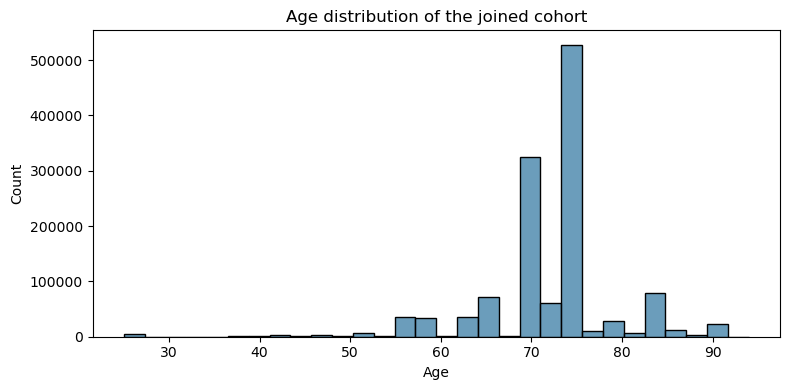

In [161]:
plt.figure(figsize=(8, 4))
sns.histplot(joined_df['age'].dropna(), bins=30, color='#3A7CA5')
plt.title('Age distribution of the joined cohort')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()